# Práctica 2 · Trading con aprendizaje por refuerzo: algoritmo REINFORCE

Esta libreta añade a la práctica 2 un tercer algoritmo, **REINFORCE**, el método de gradiente de la política de las transparencias «Métodos basados en el gradiente de la política». DQN y A3C están en `practica-2-RL-Algoritmo-DQN.ipynb` y `a3c.ipynb`.

**Por qué REINFORCE.** De lo visto en clase, era el único algoritmo que faltaba. Con él la práctica cubre las tres familias de métodos sin modelo: basados en valor (DQN), basados en la política (REINFORCE) y actor-crítico (A3C). Además une las dos prácticas: REINFORCE usa el retorno completo del episodio, igual que el control Monte Carlo de la práctica 1, y añadirle un *baseline* $V(s)$ es exactamente el paso que lleva a los métodos actor-crítico. Por eso implementamos dos versiones, **sin baseline** y **con baseline**, y medimos directamente cuánto reduce el baseline la varianza del gradiente.

Usamos **el mismo protocolo** que DQN, A3C y la práctica 1 (mismo entorno, mismos generadores, mismas series de validación y test, mismas métricas y mismo criterio de convergencia; código común en `../trader_rl.py`), y la **misma red y la misma normalización que A3C** (importadas de `a3c_lib.py`, sin modificarlo). Así la comparación entre REINFORCE y A3C depende solo de cómo se calcula el gradiente.

**Qué pide el enunciado y dónde se responde**

| Ejercicio | Dónde |
|---|---|
| 1. Implementar el algoritmo y probarlo con las cuatro funciones de precios, una serie nueva en cada episodio, y evaluar en series de test nuevas | secciones 3–5 y 7 |
| 2. Analizar las soluciones y compararlas con el agente aleatorio y con *buy & hold*; ¿es la estrategia la esperada? | secciones 7 y 8 |
| 3. Ajustar hiperparámetros: tasa de aprendizaje $\alpha$, exploración (aquí, la entropía), $\gamma$ y nº de episodios | sección 6 |
| 4. Tabla comparativa con todos los algoritmos y los *baselines*: rendimiento y tiempo de convergencia | sección 7 |

**Contenido**

1. Configuración
2. Estado y recompensa
3. El algoritmo REINFORCE
4. Qué esperamos antes de ajustar nada
5. Protocolo de evaluación y referencias
6. Ajuste de hiperparámetros
7. Entrenamiento final, resultados en test y tabla comparativa de la práctica 2
8. Análisis: política aprendida, varianza del gradiente, el factor $\gamma^t$ de las transparencias y política estocástica
9. Conclusiones y limitaciones

**Requisitos:** Python ≥ 3.10 con `torch`, `gymnasium`, `numpy`, `pandas`, `matplotlib` y `joblib`, y los ficheros `reinforce_lib.py` y `a3c_lib.py` de esta carpeta. Los resultados costosos se guardan en `cache_reinforce/` y las figuras en `figuras_reinforce/`; con `RECOMPUTE = False` se cargan sin volver a entrenar.

## 1. Configuración

In [1]:
import os
import sys
import json
import time
import random
import inspect
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from joblib import Parallel, delayed, dump, load
from IPython.display import display

warnings.filterwarnings("ignore")
torch.set_num_threads(1)

# trader_rl.py (práctica 1) está en la carpeta superior y reinforce_lib.py / a3c_lib.py en esta;
# se añaden a la ruta también para los procesos de joblib
AQUI, PADRE = str(Path.cwd()), str(Path.cwd().parent)
for ruta in (AQUI, PADRE):
    sys.path.insert(0, ruta)
os.environ["PYTHONPATH"] = os.pathsep.join([AQUI, PADRE, os.environ.get("PYTHONPATH", "")])

import a3c_lib as A
import reinforce_lib as RL
from trader_rl import (GENERATORS, make_series, val_sets, test_sets, N_VAL, N_TEST, SEED_TRAIN, SEED_CALIB, SEED_VAL, SEED_TEST,
                       evaluate, run_episode, BASELINES, summarize, convergence_episode)

GENS = list(GENERATORS)
CACHE, FIGS = Path("cache_reinforce"), Path("figuras_reinforce")
CACHE.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)

RECOMPUTE = False      # True: vuelve a entrenarlo todo; False: carga cache_reinforce/
N_CORES = max(1, min(14, (os.cpu_count() or 2) - 1))

VARIANTES = {"REINFORCE": False, "REINFORCE con baseline": True}     # nombre -> ¿usa baseline V(s)?

# Presupuesto de entrenamiento
N_CONFIGS, N_EP_BUSQUEDA, EVAL_BUSQUEDA, SEMILLAS_BUSQUEDA = 16, 1000, 100, (100, 101)   # búsqueda aleatoria
TOP_K, SEMILLAS_REEVAL = 2, (200, 201)                                                  # reevaluación con entrenamiento completo
N_EP_FINAL, EVAL_CADA, SEMILLAS_FINAL = 3000, 100, (0, 1, 2, 3, 4)                      # entrenamiento final (5 semillas)
N_EP_EXTRA, SEMILLAS_EXTRA = 1500, (300, 301)                                           # experimentos adicionales
N_EP_COSTE, REP_COSTE = 100, 3                                                          # medida del coste por episodio

COLORES = {"REINFORCE": "#d97706", "REINFORCE con baseline": "#7c2d12", "A3C": "#0891b2", "DQN": "#0f766e", "Doble DQN": "#be185d",
           "Q-Learning": "#2a78d6", "SARSA": "#7c3aed", "Monte Carlo": "#c2410c", "Buy & Hold": "#ed6a37", "Aleatorio": "#16a34a"}
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
print(f"torch {torch.__version__} | {N_CORES} procesos | RECOMPUTE={RECOMPUTE}")

torch 2.15.0+cpu | 14 procesos | RECOMPUTE=False


## 2. Estado y recompensa

Igual que en DQN y A3C, y con la misma función (`calibrar` de `a3c_lib.py`):

- **Entrada de la red:** `[(tendencia − media) / desviación, posición]`, con la media y la desviación de cada mercado calculadas en 40 series de calibración, que no se usan para nada más. La red admite valores continuos, así que no hace falta discretizar, pero sí normalizar: la tendencia se mueve en ±0,3 en *tendencia + ciclo* y en ±0,03 en los demás.
- **Recompensa:** dividida por la desviación típica del retorno por paso de cada mercado. Multiplicar todas las recompensas por una constante positiva no cambia la política óptima, y así todos los mercados trabajan en la misma escala.
- **Acciones válidas:** sin activo solo cuentan {mantener, comprar} y con activo {vender, mantener}. La política es una distribución solo sobre esas dos.

In [2]:
t0 = time.perf_counter()
ESCALAS = {g: A.calibrar(g) for g in GENS}
print(f"calibración en {time.perf_counter() - t0:.0f} s")
display(pd.DataFrame({g: {"media de la tendencia": ESCALAS[g][0][0], "desviación de la tendencia": ESCALAS[g][1][0],
                          "desviación de la recompensa por paso": ESCALAS[g][2]} for g in GENS}).T.round(4))

calibración en 1 s


,media de la tendencia,desviación de la tendencia,desviación de la recompensa por paso
Tendencia + ciclo,0.0222,0.1533,0.1063
Browniano,-0.0001,0.0250,0.0201
Reversión a la media,0.0001,0.0245,0.0205
Regímenes,-0.0005,0.0231,0.0186


## 3. El algoritmo REINFORCE

REINFORCE no aprende valores de las acciones: aprende **directamente la política** $\pi_\theta(a|s)$, una red que da la probabilidad de cada acción. En cada episodio:

1. Juega la serie entera **muestreando** sus acciones de $\pi_\theta$ (la exploración sale de ahí, no hace falta $\epsilon$-greedy).
2. Al acabar, calcula para cada paso el retorno desde ese paso hasta el final, $G_t = R_{t+1} + \gamma R_{t+2} + \dots$, hacia atrás, igual que el Monte Carlo de la práctica 1.
3. Sube la probabilidad de cada acción en proporción a lo bien que salió: $\Delta\theta \propto G_t \, \nabla \ln \pi_\theta(A_t|S_t)$.

**Con baseline.** Se resta a $G_t$ una referencia $b(s_t)$ que no depende de la acción. El gradiente esperado no cambia, pero su varianza baja mucho: ya no se premia una acción porque el episodio fue bueno en general, sino porque salió **mejor de lo esperado en ese estado**. Usamos como referencia $V_w(s_t)$, una segunda cabeza de la red que aprende a predecir $G_t$:

$$\Delta\theta \propto \big(G_t - V_w(S_t)\big)\,\nabla \ln \pi_\theta(A_t|S_t), \qquad \Delta w \propto \big(G_t - V_w(S_t)\big)\,\nabla V_w(S_t).$$

Es casi lo que hace A3C. La diferencia es que A3C no espera al final del episodio: usa un retorno de $n$ pasos completado con $V$ (*bootstrapping*). REINFORCE con baseline sigue siendo Monte Carlo.

**Decisiones de implementación**

- **Misma red que A3C** (`ActorCritic` de `a3c_lib.py`): 2 capas ocultas ReLU, una salida de política y otra de valor. Sin baseline, la cabeza de valor simplemente no se entrena.
- **Una actualización por episodio**, con la media de los términos de los 494 pasos. Adam, con tasa de aprendizaje decreciente de `lr` a `lr·lr_final`; en la práctica 1, DQN y A3C, una tasa pequeña y decreciente fue clave porque la recompensa de cada paso es casi todo ruido.
- **La exploración es la entropía.** Como en A3C, a la pérdida se resta $\beta\,H(\pi(\cdot|s))$, que impide que la política se vuelva determinista demasiado pronto. $\beta$ decrece de `beta` a `beta·beta_final`: es lo que en los algoritmos con $\epsilon$-greedy hacía el decaimiento de $\epsilon$.
- **Recorte del gradiente** (norma 1) para evitar saltos con retornos extremos.
- **El factor $\gamma^t$ de las transparencias.** El algoritmo de clase actualiza con $\alpha\,\gamma^t\,G_t\,\nabla\ln\pi$. Ese factor tiene sentido cuando importa el estado inicial del episodio, pero aquí el episodio empieza en un día cualquiera de la serie: con $\gamma = 0$ solo aprendería del primer paso, y con $\gamma = 0{,}9$ casi solo de los 20 primeros de 494. Por eso, como en la mayoría de implementaciones, no lo aplicamos, y en la sección 8.3 comprobamos qué pasa si se aplica tal cual.
- **Evaluación:** política *greedy* (la acción válida más probable; los empates, a favor de mantener), como en el resto de algoritmos. En la sección 8.4 se compara con la política estocástica.

El código (está en `reinforce_lib.py`):

In [3]:
print(inspect.getsource(RL.retornos))
print(inspect.getsource(RL.perdida))
print(inspect.getsource(RL.train_reinforce))

def retornos(R, gamma):
    """G_t = R_{t+1} + γ G_{t+1}, calculado hacia atrás desde el final del episodio."""
    G, out = 0.0, np.empty(len(R), dtype=np.float32)
    for t in range(len(R) - 1, -1, -1):
        G = R[t] + gamma * G
        out[t] = G
    return out

def perdida(net, S, A, G, hp, beta, gamma_t=False):
    """Pérdida de un episodio. Su gradiente es el de REINFORCE (con o sin baseline) más la entropía."""
    S_t, A_t, G_t = torch.from_numpy(S), torch.from_numpy(A), torch.from_numpy(G)
    logits, v = net(S_t)
    valido = VALIDAS[(S_t[:, 1] > 0.5).long()]
    logp = F.log_softmax(logits.masked_fill(~valido, -1e9), dim=1)
    logp_a = logp.gather(1, A_t[:, None]).squeeze(1)
    peso = G_t - v.detach() if hp["baseline"] else G_t          # G_t - b(s_t), con b = V(s_t) o b = 0
    if gamma_t:                                                 # versión literal de las diapositivas: α·γ^t·G_t·∇ln π
        peso = peso * torch.from_numpy(hp["gamma"] ** np.arange(len(G), dtype=n

## 4. Qué esperamos antes de ajustar nada

Hipótesis, para contrastarlas al final:

1. **Tendencia + ciclo:** *momentum* con histéresis, como todos los algoritmos anteriores.
2. **Sin baseline, mucho ruido.** El retorno completo de cientos de pasos es muy ruidoso (en la práctica 1 medimos que, con $\gamma = 0{,}99$, $G_t$ es entre 3 y 7,5 veces más ruidoso que una recompensa). Esperamos curvas inestables, mucha variación entre semillas y preferencia por $\gamma$ bajo, como le pasó a Monte Carlo.
3. **El baseline reduce la varianza del gradiente** de forma medible y mejora el resultado, sobre todo con $\gamma$ alto.
4. **Más episodios que DQN.** Una sola actualización por episodio, frente a una cada 4 pasos con lotes de experiencias en DQN, así que necesitará más episodios para converger, aunque cada uno será mucho más barato.
5. **Browniano y regímenes:** quedarse fuera o casi.

## 5. Protocolo de evaluación y referencias

El mismo que en el resto del trabajo: 30 series de validación (para ajustar y para las curvas) y 100 de test por mercado, siempre las mismas y nunca usadas para entrenar. Cada episodio de entrenamiento usa una serie nueva (semilla `SEED_TRAIN + 10 000·semilla + episodio`, igual que A3C). Primero comprobamos que las referencias coinciden con las de la práctica 1.

In [4]:
VAL, TEST = val_sets(), test_sets()
res_base, filas = {}, []
for g in GENS:
    for nombre, fabrica in BASELINES.items():
        res = evaluate(TEST[g], fabrica)
        res_base[(g, nombre)] = res
        filas.append({**summarize(res, nombre, g),
                      "% series > B&H": 100 * np.mean(res["log_ret"].values > evaluate(TEST[g], BASELINES["Buy & Hold"])["log_ret"].values)})
base = pd.DataFrame(filas).set_index(["Generador", "Agente"])
display(base[["Log-ret. medio", "Ret. geométrico (%)", "Sharpe", "Max DD (%)", "Operaciones"]].round(3))

prac1 = pd.read_csv(Path(PADRE) / "tabla_comparativa.csv").set_index(["Generador", "Agente"])
assert np.allclose(base["Log-ret. medio"], prac1.loc[base.index, "Log-ret. medio"], atol=1e-3), "las series de test no coinciden con las de la práctica 1"
print("OK: las referencias coinciden con las de la práctica 1 (mismas series de test).")

Log-ret. medio  Ret. geométrico (%)  \
Generador            Agente                                                    
Tendencia + ciclo    Aleatorio                    1.558              375.064   
                     Buy & Hold                   3.316             2655.989   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)             6.105            44704.614   
                     Contrarian (regla)          -2.973              -94.883   
Browniano            Aleatorio                   -0.187              -17.058   
                     Buy & Hold                  -0.062               -6.039   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)            -0.141              -13.135   
                     Contrarian (regla)          -0.159              -14.695   
Reversión a la media Aleatorio                   -0.169              -15.581   
                     Buy & Hold                  -0.005               -0.484   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)            -0.324              -27.707   
                     Contrarian (regla)           0.069                7.096   
Regímenes            Aleatorio                   -0.220              -19.734   
                     Buy & Hold                  -0.128              -11.981   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)            -0.126              -11.877   
                     Contrarian (regla)          -0.233              -20.796   

                                         Sharpe  Max DD (%)  Operaciones  
Generador            Agente                                               
Tendencia + ciclo    Aleatorio            1.270      80.419       164.26  
                     Buy & Hold           1.856      90.251         1.00  
                     Siempre fuera        0.000       0.000         0.00  
                     Momentum (regla)     3.098      60.429        92.59  
                     Contrarian (regla)  -0.772      95.330        92.37  
Browniano            Aleatorio           -0.311      36.044       164.26  
                     Buy & Hold           0.057      41.919         1.00  
                     Siempre fuera        0.000       0.000         0.00  
                     Momentum (regla)    -0.241      34.717       119.16  
                     Contrarian (regla)  -0.232      34.226       119.18  
Reversión a la media Aleatorio           -0.262      31.895       164.26  
                     Buy & Hold           0.154      25.678         1.00  
                     Siempre fuera        0.000       0.000         0.00  
                     Momentum (regla)    -0.627      36.937       125.95  
                     Contrarian (regla)   0.263      23.624       125.95  
Regímenes            Aleatorio           -0.423      35.366       164.26  
                     Buy & Hold          -0.043      43.733         1.00  
                     Siempre fuera        0.000       0.000         0.00  
                     Momentum (regla)    -0.225      32.118       116.54  
                     Contrarian (regla)  -0.405      36.555       116.30

OK: las referencias coinciden con las de la práctica 1 (mismas series de test).


In [5]:
def entrenar_varios(tareas, etiqueta=""):
    t0 = time.perf_counter()
    salidas = Parallel(n_jobs=N_CORES, max_nbytes=None)(delayed(RL.train_reinforce)(**t) for t in tareas)
    print(f"{etiqueta}: {len(tareas)} entrenamientos en {time.perf_counter() - t0:.0f} s")
    return salidas


def tarea(gen, hp, n_ep, seed, eval_every, gamma_t=False):
    return dict(gen=gen, hp=hp, n_ep=n_ep, seed=seed, eval_every=eval_every, escalas=ESCALAS[gen], gamma_t=gamma_t)


def _eval_job(run, idx, split, estocastica=False):
    series = (val_sets() if split == "val" else test_sets())[run["gen"]]
    pol = A.politica_de(run, idx, estocastica)
    return evaluate(series, lambda i, p=pol: p)


def curvas_validacion(runs, solo_ultimas=None):
    jobs = [(i, j) for i, r in enumerate(runs) for j in range(len(r["snap_ep"]))
            if solo_ultimas is None or j >= len(r["snap_ep"]) - solo_ultimas]
    res = Parallel(n_jobs=N_CORES, max_nbytes=None)(delayed(_eval_job)(runs[i], j, "val") for i, j in jobs)
    out = [dict() for _ in runs]
    for (i, j), r in zip(jobs, res):
        out[i][j] = float(r["log_ret"].mean())
    return out


def con_curvas(runs):
    for r, cv in zip(runs, curvas_validacion(runs)):
        r["val"] = [cv[j] for j in range(len(r["snap_ep"]))]
    return runs


def evaluar_finales(runs, estocastica=False):
    return Parallel(n_jobs=N_CORES, max_nbytes=None)(delayed(_eval_job)(r, len(r["snap_ep"]) - 1, "test", estocastica) for r in runs)

## 6. Ajuste de hiperparámetros

**Qué se ajusta** (lo que pide el enunciado, adaptado a un método de gradiente de la política):

| Enunciado | Aquí |
|---|---|
| Factor de aprendizaje $\alpha$ | `lr` (tasa de Adam) y `lr_final` (cuánto decrece) |
| Exploración $\epsilon$ con decaimiento | coeficiente de entropía `beta` y su decaimiento `beta_final` |
| Factor de descuento $\gamma$ | `gamma` ∈ {0; 0,5; 0,9; 0,99} |
| Nº de episodios | con las curvas de la reevaluación (sección 6.3) |
| (además) | tamaño de la red `hidden` |

**Cómo.** Los mismos tres pasos que en DQN y A3C, solo con las series de validación:

1. **Búsqueda aleatoria**: 16 configuraciones, las mismas para los cuatro mercados y las dos variantes, con 1000 episodios y 2 semillas. Puntuación: log-retorno medio en validación de las 3 últimas instantáneas. Los rangos son los de A3C, para que sean comparables.
2. **Reevaluación** de las 2 mejores de cada mercado y variante con el entrenamiento completo (3000 episodios) y semillas nuevas, para no quedarnos con una configuración que ganó por suerte.
3. **Nº de episodios**, a la vista de las curvas de la reevaluación.

In [6]:
CLAVES = ("lr", "lr_final", "gamma", "hidden", "beta", "beta_final")


def muestrear(n, seed=0):
    rng = random.Random(seed)
    gammas = [0.0, 0.5, 0.9, 0.99]
    return [{"id": i, "lr": float(round(10 ** rng.uniform(np.log10(3e-4), np.log10(3e-3)), 6)), "lr_final": rng.choice([1.0, 0.1]),
             "gamma": gammas[i % 4], "hidden": rng.choice([32, 64]),
             "beta": rng.choice([0.001, 0.01, 0.05]), "beta_final": rng.choice([1.0, 0.1])} for i in range(n)]


configs = muestrear(N_CONFIGS)
hp_de = lambda c, baseline: {**{k: c[k] for k in CLAVES}, "baseline": baseline}
display(pd.DataFrame(configs).set_index("id"))

,lr,lr_final,gamma,hidden,beta,beta_final
id,,,,,,
0,0.002097,0.1,0.00,32,0.010,0.1
1,0.000762,0.1,0.50,64,0.010,1.0
2,0.000959,0.1,0.90,32,0.001,0.1
3,0.002913,1.0,0.99,64,0.001,1.0
4,0.002377,0.1,0.00,64,0.050,1.0
5,0.000678,0.1,0.50,32,0.050,0.1
6,0.000831,0.1,0.90,32,0.050,1.0
7,0.000372,0.1,0.99,32,0.050,0.1
8,0.002019,0.1,0.00,32,0.050,0.1


### 6.1 Búsqueda aleatoria

In [7]:
f_busqueda = CACHE / "busqueda.csv"
if RECOMPUTE or not f_busqueda.exists():
    meta = [(v, g, c["id"], s) for v in VARIANTES for g in GENS for c in configs for s in SEMILLAS_BUSQUEDA]
    runs_b = entrenar_varios([tarea(g, hp_de(configs[c], VARIANTES[v]), N_EP_BUSQUEDA, s, EVAL_BUSQUEDA) for v, g, c, s in meta], "búsqueda aleatoria")
    curv_b = curvas_validacion(runs_b, solo_ultimas=3)
    busqueda = pd.DataFrame([{"variante": v, "gen": g, "config": c, "semilla": s, "score": float(np.mean(list(cv.values()))),
                              "tiempo (s)": r["train_time"]}
                             for (v, g, c, s), r, cv in zip(meta, runs_b, curv_b)])
    busqueda = busqueda.merge(pd.DataFrame(configs), left_on="config", right_on="id").drop(columns="id")
    busqueda.to_csv(f_busqueda, index=False)
else:
    busqueda = pd.read_csv(f_busqueda)
print(f"{len(busqueda)} entrenamientos de {N_EP_BUSQUEDA} episodios.")

256 entrenamientos de 1000 episodios.


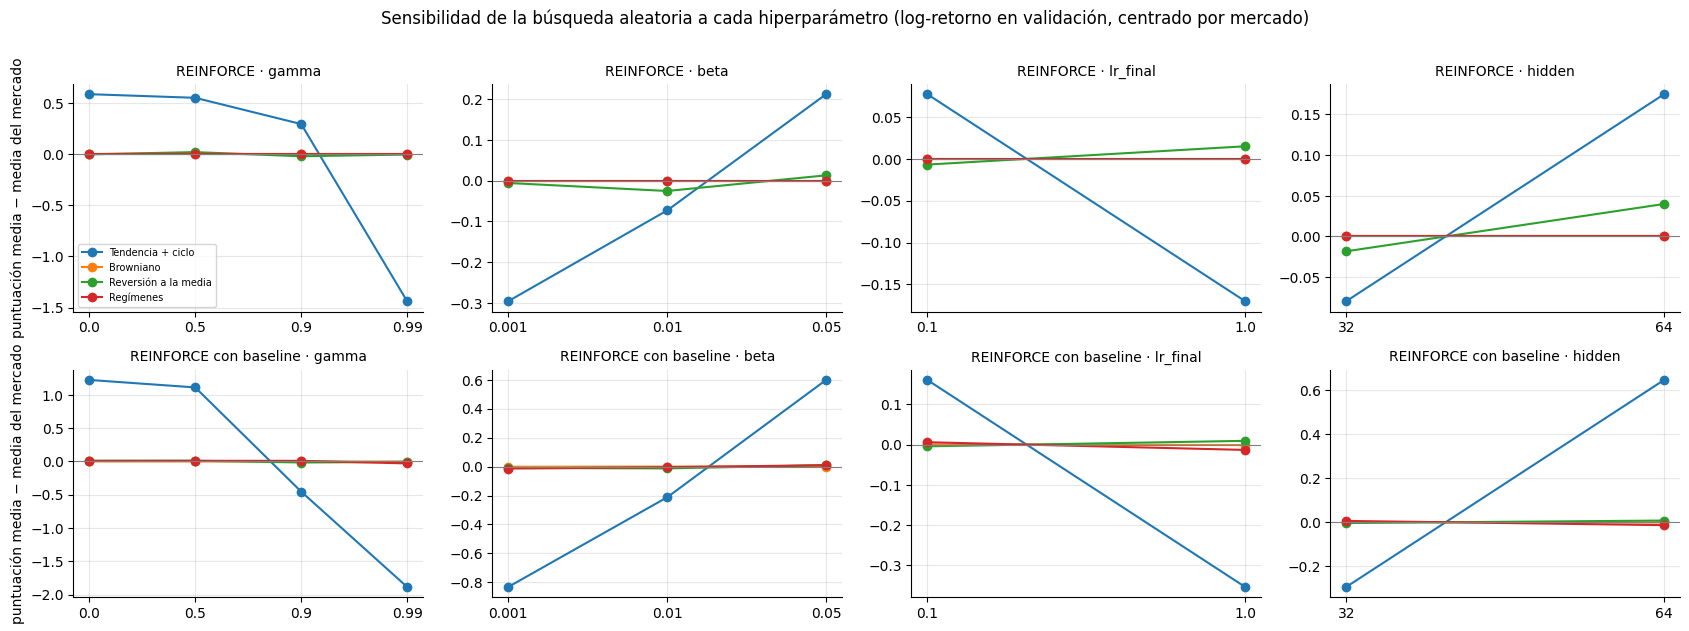

γ (mejor configuración con ese γ)             0.00   0.50   0.90   0.99
variante               gen                                             
REINFORCE              Browniano             0.000  0.000  0.000  0.000
                       Regímenes             0.000  0.000  0.000  0.000
                       Reversión a la media  0.115  0.114  0.033  0.118
                       Tendencia + ciclo     6.220  6.217  6.126  4.523
REINFORCE con baseline Browniano             0.000  0.000  0.000  0.000
                       Regímenes             0.000  0.000  0.000  0.000
                       Reversión a la media  0.080  0.095  0.000  0.023
                       Tendencia + ciclo     6.226  6.249  5.891  3.909

In [8]:
# Sensibilidad: para cada valor de cada hiperparámetro, puntuación media de las configuraciones que lo usan
bm = busqueda.groupby(["variante", "gen", "config"] + list(CLAVES), as_index=False).score.mean()
fig, axs = plt.subplots(len(VARIANTES), 4, figsize=(17, 6.2), sharey=False)
for i, v in enumerate(VARIANTES):
    for j, col in enumerate(["gamma", "beta", "lr_final", "hidden"]):
        ax = axs[i, j]
        for g in GENS:
            d = bm[(bm.variante == v) & (bm.gen == g)].groupby(col).score.mean()
            d = d - bm[(bm.variante == v) & (bm.gen == g)].score.mean()      # centrada por mercado: escalas muy distintas
            ax.plot(range(len(d)), d.values, "o-", label=g)
            ax.set_xticks(range(len(d)), [str(x) for x in d.index])
        ax.axhline(0, color="gray", lw=0.8)
        ax.set_title(f"{v} · {col}", fontsize=10)
axs[0, 0].set_ylabel("puntuación media − media del mercado")
axs[1, 0].set_ylabel("puntuación media − media del mercado")
axs[0, 0].legend(fontsize=7)
fig.suptitle("Sensibilidad de la búsqueda aleatoria a cada hiperparámetro (log-retorno en validación, centrado por mercado)", y=1.01)
plt.tight_layout()
plt.savefig(FIGS / "sensibilidad_busqueda.png", bbox_inches="tight")
plt.show()

display(bm.groupby(["variante", "gen", "gamma"]).score.max().unstack().round(3).rename_axis(columns="γ (mejor configuración con ese γ)"))

**Qué sale de la búsqueda**

- **$\gamma$ alto hunde el resultado en *tendencia + ciclo*:** con $\gamma = 0{,}99$ la mejor configuración se queda en 4,52 (sin baseline) y 3,91 (con baseline), frente a 6,2 con $\gamma$ = 0 o 0,5. Es lo mismo que le pasaba a Monte Carlo en la práctica 1: REINFORCE usa el retorno completo, y con un horizonte de cientos de pasos ese retorno es casi todo ruido.
- **En *browniano* y *regímenes* ninguna configuración opera** (todas, sin baseline; el 94 % y el 88 % con baseline). La mejor puntuación es 0 en todos los casos, así que la «elegida» es un empate y nos quedamos con la primera. Al menos REINFORCE no se deja engañar por el ruido, al contrario que A3C en el *browniano*.
- ***Reversión a la media* es el mercado difícil:** las mejores puntuaciones apenas llegan a 0,12 y muchas configuraciones acaban sin operar (31 % sin baseline, 56 % con baseline).
- **Más exploración ayuda.** La entropía alta ($\beta = 0{,}05$) es la mejor en los dos mercados con señal (en *tendencia*, 5,83 de media frente a 5,32 con $\beta = 0{,}001$), y en *reversión* también ayuda mantenerla constante (`beta_final = 1`: 0,065 frente a 0,008). Con poca exploración la política se vuelve determinista antes de encontrar la señal.

### 6.2 Reevaluación de las mejores configuraciones

In [9]:
f_reeval, f_params = CACHE / "reevaluacion.csv", CACHE / "mejores_params.json"
if RECOMPUTE or not f_reeval.exists():
    ranking = busqueda.groupby(["variante", "gen", "config"]).score.mean().reset_index()
    top = ranking.sort_values(["variante", "gen", "score"], ascending=[True, True, False]).groupby(["variante", "gen"]).head(TOP_K)
    meta = [(r.variante, r.gen, int(r.config), s) for r in top.itertuples() for s in SEMILLAS_REEVAL]
    runs_r = con_curvas(entrenar_varios([tarea(g, hp_de(configs[c], VARIANTES[v]), N_EP_FINAL, s, EVAL_CADA) for v, g, c, s in meta], "reevaluación"))
    filas, curvas = [], {}
    for (v, g, c, s), run in zip(meta, runs_r):
        filas.append({"variante": v, "gen": g, "config": c, "semilla": s, "score": float(np.mean(run["val"][-3:]))})
        curvas.setdefault((v, g, c), []).append((run["snap_ep"], run["val"]))
    reeval = pd.DataFrame(filas).groupby(["variante", "gen", "config"]).score.mean().reset_index()
    reeval = reeval.merge(pd.DataFrame(configs), left_on="config", right_on="id").drop(columns="id")
    reeval.to_csv(f_reeval, index=False)
    dump({k: {"ep": v_[0][0], "val": np.mean([x[1] for x in v_], 0)} for k, v_ in curvas.items()}, CACHE / "curvas_reeval.joblib")
    elegida = reeval.sort_values("score", ascending=False, kind="stable").groupby(["variante", "gen"]).head(1)
    MEJORES = {f"{r.variante}|{r.gen}": {**{k: (int(getattr(r, k)) if k == "hidden" else float(getattr(r, k))) for k in CLAVES},
                                         "baseline": VARIANTES[r.variante], "config": int(r.config)} for r in elegida.itertuples()}
    json.dump(MEJORES, open(f_params, "w", encoding="utf-8"), indent=1, ensure_ascii=False)
else:
    reeval = pd.read_csv(f_reeval)
    MEJORES = json.load(open(f_params, encoding="utf-8"))
mejor = lambda v, g: {k: x for k, x in MEJORES[f"{v}|{g}"].items() if k != "config"}
display(reeval.sort_values(["variante", "gen", "score"], ascending=[True, True, False]).reset_index(drop=True).round(4))
print("Hiperparámetros elegidos:")
display(pd.DataFrame({k: {c: MEJORES[k][c] for c in CLAVES} for k in MEJORES}).T)

,variante,gen,config,score,lr,lr_final,gamma,hidden,beta,beta_final
0,REINFORCE,Browniano,0,0.0000,0.0021,0.1,0.00,32,0.010,0.1
1,REINFORCE,Browniano,1,0.0000,0.0008,0.1,0.50,64,0.010,1.0
2,REINFORCE,Regímenes,0,0.0000,0.0021,0.1,0.00,32,0.010,0.1
3,REINFORCE,Regímenes,1,0.0000,0.0008,0.1,0.50,64,0.010,1.0
4,REINFORCE,Reversión a la media,3,0.0957,0.0029,1.0,0.99,64,0.001,1.0
5,REINFORCE,Reversión a la media,4,0.0242,0.0024,0.1,0.00,64,0.050,1.0
6,REINFORCE,Tendencia + ciclo,1,6.2876,0.0008,0.1,0.50,64,0.010,1.0
7,REINFORCE,Tendencia + ciclo,12,6.2073,0.0015,0.1,0.00,32,0.050,0.1
8,REINFORCE con baseline,Browniano,0,0.0000,0.0021,0.1,0.00,32,0.010,0.1
9,REINFORCE con baseline,Browniano,1,0.0000,0.0008,0.1,0.50,64,0.010,1.0


Hiperparámetros elegidos:


,lr,lr_final,gamma,hidden,beta,beta_final
REINFORCE|Tendencia + ciclo,0.000762,0.1,0.50,64.0,0.010,1.0
REINFORCE con baseline|Tendencia + ciclo,0.002097,0.1,0.00,32.0,0.010,0.1
REINFORCE con baseline|Reversión a la media,0.001516,1.0,0.50,32.0,0.050,1.0
REINFORCE|Reversión a la media,0.002913,1.0,0.99,64.0,0.001,1.0
REINFORCE|Browniano,0.002097,0.1,0.00,32.0,0.010,0.1
REINFORCE|Regímenes,0.002097,0.1,0.00,32.0,0.010,0.1
REINFORCE con baseline|Browniano,0.002097,0.1,0.00,32.0,0.010,0.1
REINFORCE con baseline|Regímenes,0.002097,0.1,0.00,32.0,0.010,0.1


### 6.3 Curvas de la reevaluación y número de episodios

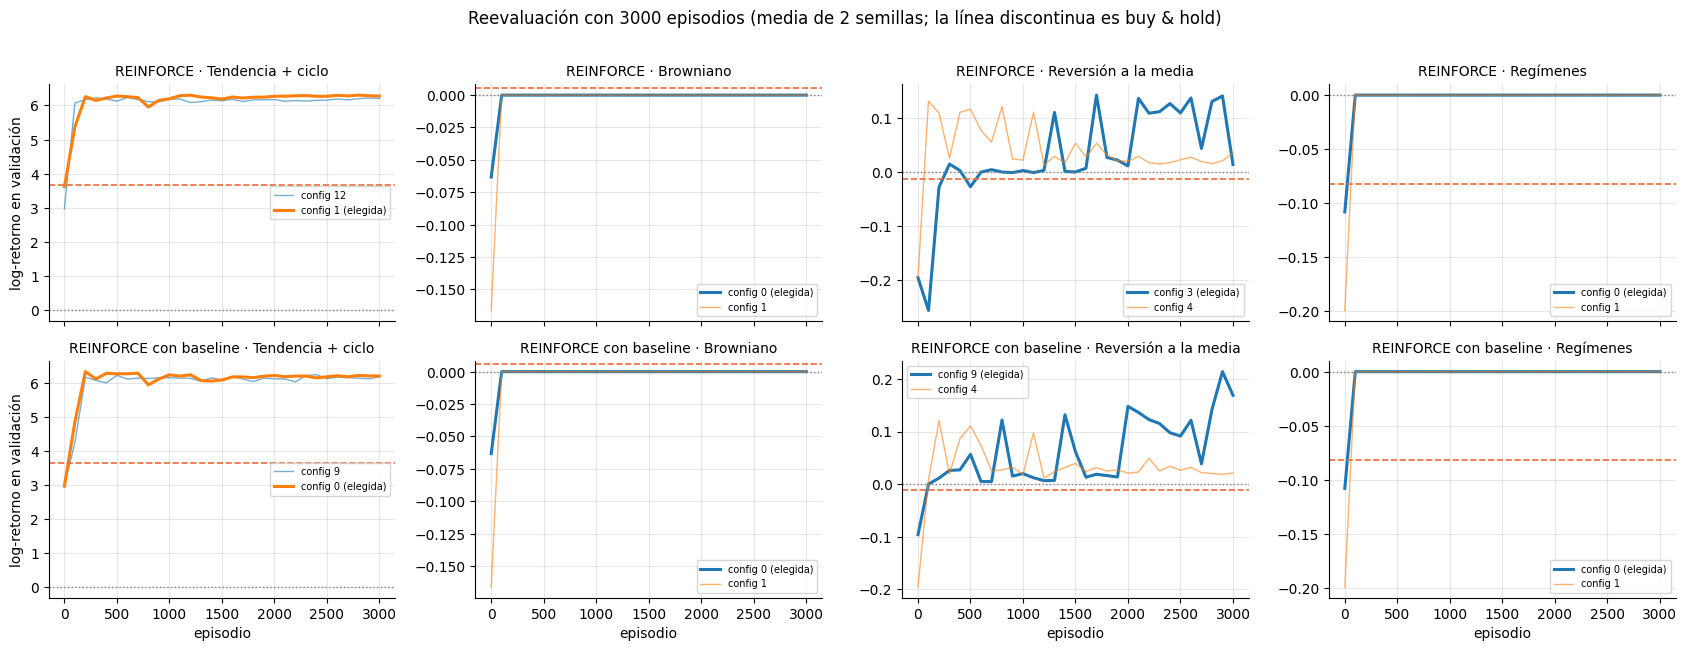

In [10]:
curvas = load(CACHE / "curvas_reeval.joblib")
fig, axs = plt.subplots(len(VARIANTES), 4, figsize=(17, 6.4), sharex=True)
for i, v in enumerate(VARIANTES):
    for j, g in enumerate(GENS):
        ax = axs[i, j]
        for (vv, gg, c), d in curvas.items():
            if vv == v and gg == g:
                elegido = MEJORES[f"{v}|{g}"]["config"] == c
                ax.plot(d["ep"], d["val"], lw=2.2 if elegido else 1, alpha=1 if elegido else 0.6, label=f"config {c}" + (" (elegida)" if elegido else ""))
        ax.axhline(evaluate(VAL[g], BASELINES["Buy & Hold"])["log_ret"].mean(), color=COLORES["Buy & Hold"], ls="--", lw=1.2)
        ax.axhline(0, color="gray", ls=":", lw=1)
        ax.set_title(f"{v} · {g}", fontsize=10)
        ax.legend(fontsize=7)
    axs[i, 0].set_ylabel("log-retorno en validación")
for ax in axs[-1]:
    ax.set_xlabel("episodio")
fig.suptitle("Reevaluación con 3000 episodios (media de 2 semillas; la línea discontinua es buy & hold)", y=1.01)
plt.tight_layout()
plt.savefig(FIGS / "curvas_reevaluacion.png", bbox_inches="tight")
plt.show()

**Lectura y número de episodios.**

- **Elegidas:** en *tendencia + ciclo*, $\gamma = 0{,}5$ sin baseline (6,29 en validación) y $\gamma = 0$ con baseline (6,22). En *reversión*, $\gamma = 0{,}99$ sin baseline (0,096) y $\gamma = 0{,}5$ con baseline (0,175). En *browniano* y *regímenes*, la primera configuración (empate en 0).
- **3000 episodios.** En *tendencia + ciclo* las curvas se estabilizan hacia los 300 episodios y no cambian después. En *reversión* siguen subiendo, con muchos altibajos, hasta el final, así que 3000 es el mínimo razonable y probablemente más episodios ayudarían algo. Usamos el mismo número que los algoritmos tabulares para poder compararlos.

## 7. Entrenamiento final, curvas de aprendizaje y resultados en test

Con los hiperparámetros elegidos se entrenan **5 semillas por mercado y variante, con 3000 episodios cada una**, y se evalúa la política *greedy* en validación cada 100 episodios. El episodio de convergencia se calcula con el criterio común: el primero a partir del cual la curva suavizada ya no sale de una banda en torno a su valor final.

In [11]:
f_final = CACHE / "runs_final.joblib"
if RECOMPUTE or not f_final.exists():
    tareas = [tarea(g, mejor(v, g), N_EP_FINAL, s, EVAL_CADA) for v in VARIANTES for g in GENS for s in SEMILLAS_FINAL]
    RUNS = con_curvas(entrenar_varios(tareas, "entrenamiento final"))
    for r, (v, g, s) in zip(RUNS, [(v, g, s) for v in VARIANTES for g in GENS for s in SEMILLAS_FINAL]):
        r["variante"] = v
    dump(RUNS, f_final)
else:
    RUNS = load(f_final)
runs_de = lambda v, g, runs=None: [r for r in (runs or RUNS) if r["variante"] == v and r["gen"] == g]
print(f"{len(RUNS)} entrenamientos finales")

40 entrenamientos finales


**Coste por episodio.** Medido en serie, sin validación y con un solo proceso (el mínimo de 3 repeticiones de 100 episodios), igual que en el resto del trabajo.

In [12]:
def coste(v, g):
    return 1000 * min(RL.train_reinforce(g, mejor(v, g), N_EP_COSTE, 900, eval_every=N_EP_COSTE, escalas=ESCALAS[g])["train_time"]
                      for _ in range(REP_COSTE)) / N_EP_COSTE


f_coste = CACHE / "coste_ms.csv"
if RECOMPUTE or not f_coste.exists():
    coste_df = pd.DataFrame([{"variante": v, "gen": g, "ms": coste(v, g)} for v in VARIANTES for g in GENS])
    coste_df.to_csv(f_coste, index=False)
else:
    coste_df = pd.read_csv(f_coste)
COSTE = {(r.variante, r.gen): r.ms for r in coste_df.itertuples()}
display(coste_df.pivot(index="gen", columns="variante", values="ms").loc[GENS].round(1).rename_axis("ms por episodio"))

variante,REINFORCE,REINFORCE con baseline
ms por episodio,,
Tendencia + ciclo,23.3,22.5
Browniano,23.4,21.5
Reversión a la media,23.3,23.7
Regímenes,22.7,22.8


### Curvas de aprendizaje

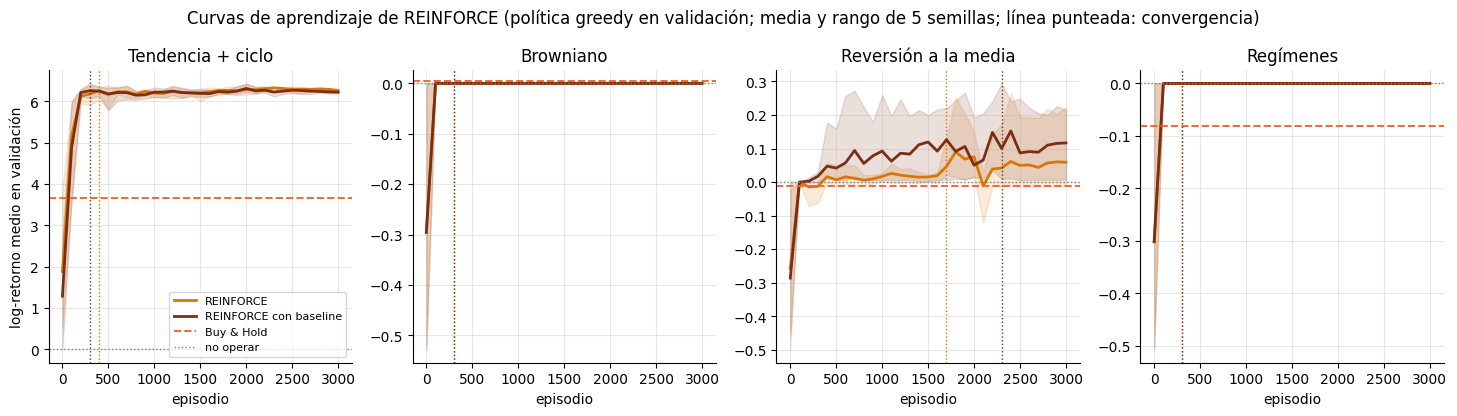

In [13]:
conv_de = lambda runs: float(np.median([convergence_episode(list(r["snap_ep"]), r["val"]) for r in runs]))
fig, axs = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, g in zip(axs, GENS):
    for v in VARIANTES:
        rs = runs_de(v, g)
        val = np.array([r["val"] for r in rs])
        ep = rs[0]["snap_ep"]
        ax.plot(ep, val.mean(0), color=COLORES[v], lw=2, label=v)
        ax.fill_between(ep, val.min(0), val.max(0), color=COLORES[v], alpha=0.15)
        ax.axvline(conv_de(rs), color=COLORES[v], ls=":", lw=1)
    ax.axhline(evaluate(VAL[g], BASELINES["Buy & Hold"])["log_ret"].mean(), color=COLORES["Buy & Hold"], ls="--", lw=1.4, label="Buy & Hold")
    ax.axhline(0, color="gray", ls=":", lw=1, label="no operar")
    ax.set_title(g)
    ax.set_xlabel("episodio")
axs[0].set_ylabel("log-retorno medio en validación")
axs[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Curvas de aprendizaje de REINFORCE (política greedy en validación; media y rango de 5 semillas; línea punteada: convergencia)", y=1.04)
plt.savefig(FIGS / "curvas_aprendizaje.png", bbox_inches="tight")
plt.show()

### Evaluación en test

In [14]:
t0 = time.perf_counter()
EVAL_RUNS = evaluar_finales(RUNS)
print(f"{len(RUNS)} evaluaciones en test en {time.perf_counter() - t0:.0f} s")


def fila(res_list, nombre, g, runs=None, ms=None):
    res = pd.concat(res_list, ignore_index=True)
    bh = res_base[(g, "Buy & Hold")]["log_ret"].values
    extra = {"% series > B&H": 100 * np.mean(res["log_ret"].values > np.tile(bh, len(res) // len(bh)))}
    if runs is not None:
        conv = conv_de(runs)
        extra.update({"Std log-ret. entre semillas": float(np.std([d["log_ret"].mean() for d in res_list])),
                      "Episodios hasta convergencia": conv, "ms/episodio": ms, "Tiempo hasta convergencia (s)": conv * ms / 1000})
    return summarize(res, nombre, g, extra)


filas = [{**summarize(res_base[(g, n)], n, g), "% series > B&H": base.loc[(g, n), "% series > B&H"]} for g in GENS for n in BASELINES]
for v in VARIANTES:
    for g in GENS:
        idx = [i for i, r in enumerate(RUNS) if r["variante"] == v and r["gen"] == g]
        filas.append(fila([EVAL_RUNS[i] for i in idx], v, g, [RUNS[i] for i in idx], COSTE[(v, g)]))
tabla = pd.DataFrame(filas).set_index(["Generador", "Agente"])

FMT = {"Log-ret. medio": "{:.3f}", "Ret. geométrico (%)": "{:,.1f}", "Ret. mediano (%)": "{:,.1f}", "% series > B&H": "{:.0f}", "Sharpe": "{:.2f}",
       "Max DD (%)": "{:.1f}", "Operaciones": "{:.1f}", "% tiempo invertido": "{:.1f}", "Std log-ret. entre semillas": "{:.3f}",
       "Episodios hasta convergencia": "{:.0f}", "ms/episodio": "{:.1f}", "Tiempo hasta convergencia (s)": "{:.1f}"}
COLS = list(FMT)
ORDEN = list(VARIANTES) + ["Buy & Hold", "Aleatorio", "Siempre fuera", "Momentum (regla)", "Contrarian (regla)"]
principal = tabla.loc[[(g, a) for g in GENS for a in ORDEN], COLS]
display(principal.style.format(FMT, na_rep="—"))

40 evaluaciones en test en 20 s


**Análisis de los resultados en test** (5 semillas × 100 series)

- **Tendencia + ciclo:** 6,486 (±0,017) sin baseline y 6,456 (±0,033) con baseline, frente a 3,32 de *buy & hold* y 6,11 de la regla de *momentum*. Supera a *buy & hold* en el 99 % de las series con unas 30 operaciones por episodio, frente a las 93 de la regla. Es la estrategia esperada (*momentum* con histéresis, sección 8.1) y **el resultado más estable de todos los algoritmos del trabajo**: la desviación entre semillas es la mitad que la de Monte Carlo y 10 veces menor que la de A3C. Converge en 300–400 episodios (7–9 s).
- **Browniano:** 0 exacto con las dos variantes: no opera nunca, que es lo correcto en un mercado sin señal y con deriva logarítmica negativa. Mejor que *buy & hold* (−0,062), que el aleatorio (−0,187) y que A3C (−0,073).
- **Reversión a la media:** es su punto débil. 0,053 (±0,064) sin baseline y 0,085 (±0,066) con baseline: ganan a *buy & hold* (−0,005) en el 60 % y el 73 % de las series, pero quedan por debajo de todos los demás algoritmos, y la versión sin baseline incluso por debajo de la regla fija *contrarian* (0,069). Además, la variación entre semillas es tan grande como la media: unas semillas aprenden bien el *contrarian* y otras casi no operan. Converge tarde: 1700–2300 episodios (40–55 s).
- **Regímenes:** 0, no opera, igual que SARSA y A3C. No pierde (*buy & hold* pierde un 12 %), pero tampoco saca la pequeña ganancia que consiguen Q-Learning (+0,040), Monte Carlo y DQN (+0,03).
- **Coste:** unos 23 ms por episodio con un solo proceso. Es unas 3 veces más que los tabulares (8–11 ms) y unas 6 veces menos que DQN (134–204 ms), porque solo hay una actualización de la red por episodio.

### Tabla comparativa de la práctica 2 (ejercicio 4)

Todos los algoritmos del trabajo con el mismo protocolo y las mismas 100 series de test: los tabulares de la práctica 1 (`../tabla_comparativa.csv`), DQN (`resultados_dqn.csv`), A3C (`resultados_a3c.csv`) y REINFORCE. Rendimiento: log-retorno medio en test (± desviación entre semillas). Convergencia: episodios hasta converger y su equivalente en segundos (episodios × ms por episodio). En A3C son segundos de reloj con 4 trabajadores en paralelo; el resto, con un solo proceso.

In [15]:
dqn = pd.read_csv("resultados_dqn.csv").set_index(["Generador", "Agente"])
a3c = pd.read_csv("resultados_a3c.csv", encoding="utf-8-sig").set_index(["Generador", "Agente"])
FUENTE = {"Q-Learning": prac1, "SARSA": prac1, "Monte Carlo": prac1, "DQN": dqn, "Doble DQN": dqn, "A3C": a3c,
          "REINFORCE": principal, "REINFORCE con baseline": principal}
ALGOS = list(FUENTE)

filas = []
for g in GENS:
    for a in ALGOS + ["Buy & Hold", "Aleatorio"]:
        src = FUENTE.get(a, principal)
        r = src.loc[(g, a)]
        filas.append({"Generador": g, "Agente": a, "Familia": {"Q-Learning": "tabular (TD)", "SARSA": "tabular (TD)", "Monte Carlo": "tabular (MC)",
                      "DQN": "valor (red)", "Doble DQN": "valor (red)", "A3C": "actor-crítico", "REINFORCE": "política (MC)",
                      "REINFORCE con baseline": "política (MC) + V(s)"}.get(a, "referencia"),
                      "Log-ret. medio": r["Log-ret. medio"], "Std log-ret. entre semillas": r.get("Std log-ret. entre semillas", np.nan),
                      "% series > B&H": r["% series > B&H"], "Operaciones": r["Operaciones"],
                      "Episodios hasta convergencia": r.get("Episodios hasta convergencia", np.nan), "ms/episodio": r.get("ms/episodio", np.nan)})
comp = pd.DataFrame(filas).set_index(["Generador", "Agente"])
comp["Tiempo hasta convergencia (s)"] = comp["Episodios hasta convergencia"] * comp["ms/episodio"] / 1000
comp.round(4).to_csv("tabla_comparativa_practica2.csv", encoding="utf-8-sig")
display(comp.style.format({**FMT, "Familia": "{}"}, na_rep="—"))

Log-retorno medio en test (entre paréntesis, desviación entre semillas):


,Q-Learning,SARSA,Monte Carlo,DQN,Doble DQN,A3C,REINFORCE,REINFORCE con baseline,Buy & Hold,Aleatorio
Tendencia + ciclo,+6.338 (±0.102),+6.316 (±0.234),+6.522 (±0.039),+6.092 (±0.182),+6.241 (±0.101),+6.412 (±0.189),+6.486 (±0.017),+6.456 (±0.033),+3.316,+1.558
Browniano,+0.000 (±0.000),+0.000 (±0.000),-0.012 (±0.025),-0.005 (±0.010),-0.005 (±0.010),-0.073 (±0.040),+0.000 (±0.000),+0.000 (±0.000),-0.062,-0.187
Reversión a la media,+0.155 (±0.042),+0.203 (±0.025),+0.238 (±0.015),+0.175 (±0.045),+0.201 (±0.020),+0.114 (±0.044),+0.053 (±0.064),+0.085 (±0.066),-0.005,-0.169
Regímenes,+0.040 (±0.022),+0.000 (±0.000),+0.031 (±0.011),+0.030 (±0.040),+0.008 (±0.011),+0.000 (±0.000),+0.000 (±0.000),+0.000 (±0.000),-0.128,-0.220


Convergencia (episodios / segundos):


,Q-Learning,SARSA,Monte Carlo,DQN,Doble DQN,A3C,REINFORCE,REINFORCE con baseline
Tendencia + ciclo,300 ep. / 2.4 s,500 ep. / 4.0 s,500 ep. / 4.8 s,60 ep. / 9.1 s,60 ep. / 9.2 s,350 ep. / 8.6 s,400 ep. / 9.3 s,300 ep. / 6.8 s
Browniano,400 ep. / 4.2 s,1700 ep. / 13.0 s,700 ep. / 6.5 s,80 ep. / 10.7 s,80 ep. / 11.0 s,800 ep. / 19.8 s,300 ep. / 7.0 s,300 ep. / 6.4 s
Reversión a la media,2200 ep. / 18.6 s,1600 ep. / 14.1 s,1600 ep. / 17.3 s,160 ep. / 23.3 s,180 ep. / 29.0 s,750 ep. / 50.5 s,1700 ep. / 39.7 s,2300 ep. / 54.6 s
Regímenes,2000 ep. / 16.6 s,600 ep. / 5.5 s,1300 ep. / 11.5 s,140 ep. / 18.8 s,180 ep. / 26.4 s,150 ep. / 4.1 s,300 ep. / 6.8 s,300 ep. / 6.8 s


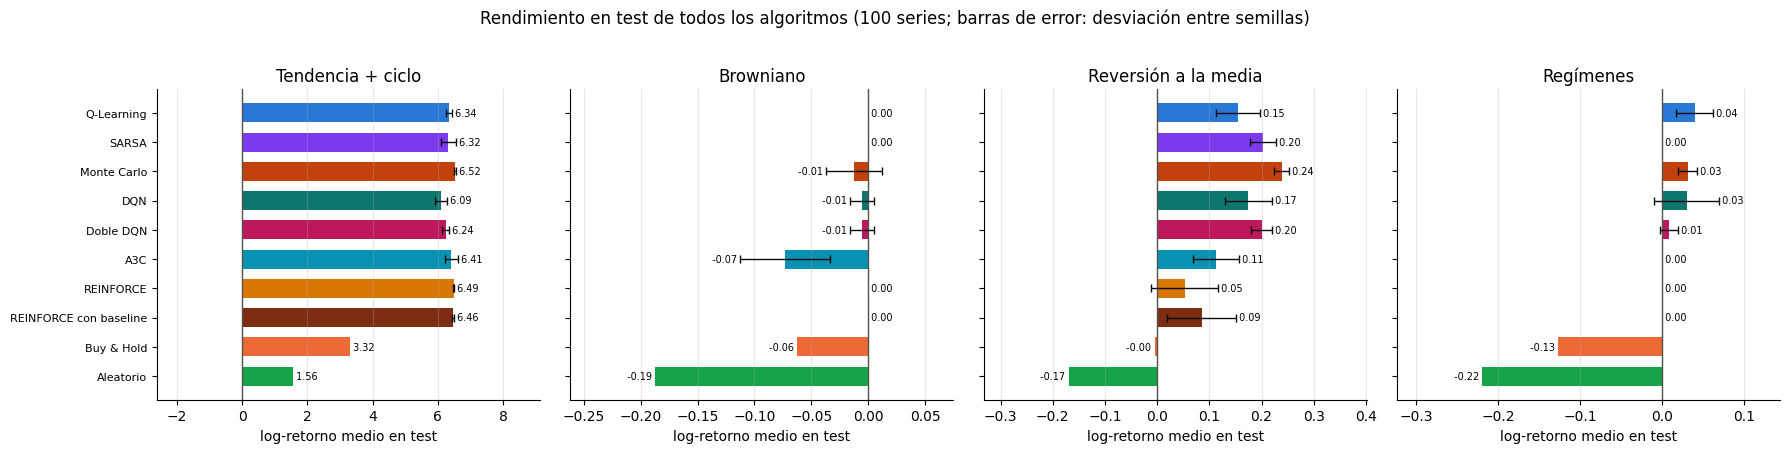

In [16]:
resumen = pd.DataFrame({a: [f"{comp.loc[(g, a), 'Log-ret. medio']:+.3f}" + (f" (±{comp.loc[(g, a), 'Std log-ret. entre semillas']:.3f})" if a in ALGOS else "")
                            for g in GENS] for a in ALGOS + ["Buy & Hold", "Aleatorio"]}, index=GENS)
print("Log-retorno medio en test (entre paréntesis, desviación entre semillas):")
display(resumen)
convs = pd.DataFrame({a: [f"{comp.loc[(g, a), 'Episodios hasta convergencia']:.0f} ep. / {comp.loc[(g, a), 'Tiempo hasta convergencia (s)']:.1f} s" for g in GENS]
                      for a in ALGOS}, index=GENS)
print("Convergencia (episodios / segundos):")
display(convs)

fig, axs = plt.subplots(1, 4, figsize=(18, 4.4))
mostrar = ALGOS + ["Buy & Hold", "Aleatorio"]
for ax, g in zip(axs, GENS):
    vals = [comp.loc[(g, a), "Log-ret. medio"] for a in mostrar]
    errs = [comp.loc[(g, a), "Std log-ret. entre semillas"] if a in ALGOS else 0 for a in mostrar]
    ax.barh(range(len(mostrar)), vals, color=[COLORES[a] for a in mostrar], height=0.65)
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_yticks(range(len(mostrar)), mostrar if g == GENS[0] else [""] * len(mostrar), fontsize=8)
    ax.invert_yaxis()
    ax.set_title(g)
    ax.set_xlabel("log-retorno medio en test")
    for k, (v, e) in enumerate(zip(vals, errs)):
        if e > 0:
            ax.errorbar(v, k, xerr=e, fmt="none", ecolor="#0b0b0b", capsize=3, lw=1)
        ax.text(v + e if v >= 0 else v - e, k, f" {v:.2f} ", va="center", ha="left" if v >= 0 else "right", fontsize=7)
    lo, hi = min(0, min(vals)), max(0, max(vals))
    pad = 0.4 * (hi - lo)
    ax.set_xlim(lo - pad, hi + pad)
    ax.grid(axis="y", visible=False)
fig.suptitle("Rendimiento en test de todos los algoritmos (100 series; barras de error: desviación entre semillas)", y=1.02)
plt.tight_layout()
plt.savefig(FIGS / "comparativa.png", bbox_inches="tight")
plt.show()

**Lectura de la tabla comparativa**

- **Tendencia + ciclo:** todos los algoritmos aprenden el mismo *momentum* y quedan entre 6,09 y 6,52. REINFORCE es el segundo (6,49), muy cerca de Monte Carlo (6,52), y el más estable. Que los dos mejores sean los dos métodos Monte Carlo (uno tabular, otro de política) no es casualidad: con el horizonte corto que eligieron, el retorno completo no les penaliza.
- **Reversión a la media:** aquí se separan las familias. Los tabulares (Monte Carlo 0,238, SARSA 0,203) y Doble DQN (0,201) son los mejores; los de gradiente de la política, los peores (A3C 0,114, REINFORCE 0,05–0,09). La señal es débil, y estimar un gradiente con un episodio de 494 pasos de ruido da actualizaciones mucho más ruidosas que corregir el valor de una acción paso a paso.
- **Regímenes:** SARSA, A3C y REINFORCE acaban sin operar, mientras que Q-Learning, DQN y Monte Carlo sí sacan un 3–4 %. Una explicación probable es que los tres primeros valoran la política exploratoria que están siguiendo, que paga comisiones al explorar, y ante una señal tan débil les compensa quedarse fuera.
- **Browniano:** lo mejor es no operar, y casi todos lo consiguen; solo A3C pierde de forma apreciable.
- **Convergencia y coste:** DQN es el que menos episodios necesita (60–180), pero cada episodio es el más caro. REINFORCE y A3C necesitan cientos o miles de episodios, más baratos. En segundos, los tabulares son los más rápidos tanto en *tendencia + ciclo* (2–5 s frente a 7–9 s de los métodos con red) como en *reversión* (14–19 s frente a 23–55 s).
- **Conclusión de la tabla:** con un estado de solo dos variables, **ningún método con red mejora a los tabulares**. Lo que aporta cada algoritmo nuevo es entender por qué: DQN muestra el coste de generalizar, A3C el efecto del paralelismo y REINFORCE el de usar el retorno completo.

## 8. Análisis

### 8.1 Política aprendida

Mismo gráfico que en A3C: para cada tendencia, fracción de las 5 semillas que quedan invertidas después de actuar. En la fila «fuera», verde es que compra; en la fila «dentro», verde es que mantiene y blanco que vende.

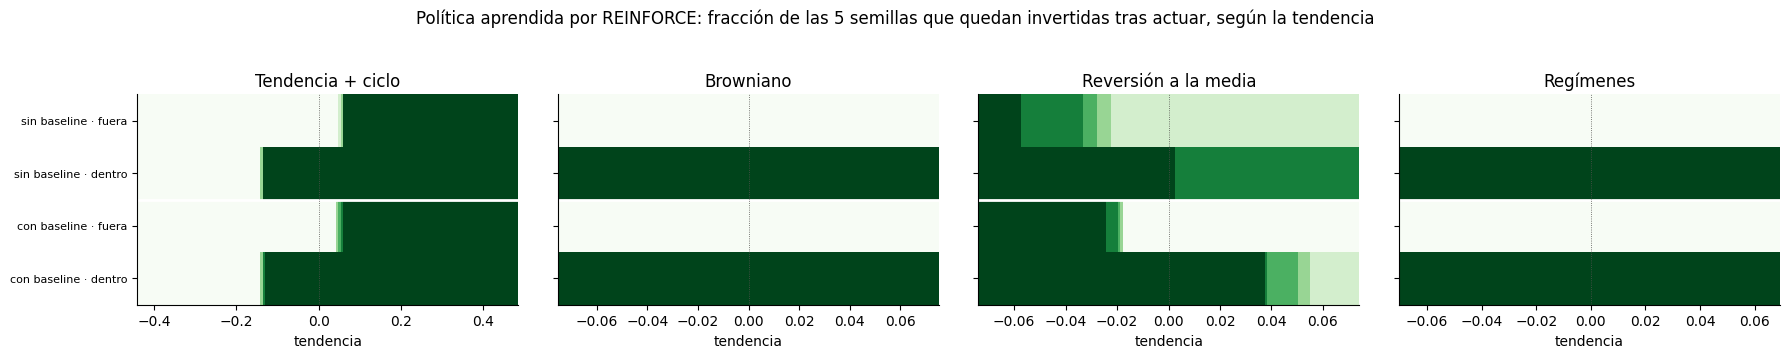

In [17]:
def mapa_politica(runs, g):
    mu, sd = ESCALAS[g][0][0], ESCALAS[g][1][0]
    xs = np.linspace(mu - 3 * sd, mu + 3 * sd, 161)
    pols = [A.politica_de(r, len(r["snap_ep"]) - 1) for r in runs]
    M = []
    for pos in (0, 1):
        acts = np.array([[p(np.array([t, pos], dtype=np.float32)) for t in xs] for p in pols])
        M.append(((acts == 2) if pos == 0 else (acts != 0)).mean(0))
    return xs, np.array(M)


fig, axs = plt.subplots(1, 4, figsize=(18, 3.4))
for ax, g in zip(axs, GENS):
    filas_m, etiquetas = [], []
    for v in VARIANTES:
        xs, M = mapa_politica(runs_de(v, g), g)
        filas_m += [M[0], M[1]]
        corto = "sin baseline" if v == "REINFORCE" else "con baseline"
        etiquetas += [f"{corto} · fuera", f"{corto} · dentro"]
    dx = xs[1] - xs[0]
    ax.pcolormesh(np.append(xs - dx / 2, xs[-1] + dx / 2), np.arange(len(filas_m) + 1), np.array(filas_m), cmap="Greens", vmin=0, vmax=1, shading="flat")
    ax.axhline(2, color="white", lw=2)
    ax.axvline(0, color="#52514e", lw=0.6, ls=":")
    ax.set_ylim(len(filas_m), 0)
    ax.set_yticks(np.arange(len(filas_m)) + 0.5, etiquetas if g == GENS[0] else [""] * len(filas_m), fontsize=8)
    ax.set_title(g)
    ax.set_xlabel("tendencia")
    ax.grid(False)
fig.suptitle("Política aprendida por REINFORCE: fracción de las 5 semillas que quedan invertidas tras actuar, según la tendencia", y=1.04)
plt.tight_layout()
plt.savefig(FIGS / "politicas.png", bbox_inches="tight")
plt.show()

**Lectura de la política**

- **Tendencia + ciclo:** *momentum* con histéresis idéntico en las 5 semillas y en las dos variantes: estando fuera compra cuando la tendencia pasa de +0,05, y estando dentro mantiene hasta que baja de −0,14.
- **Browniano y regímenes:** la fila «fuera» está en blanco: nunca compra. La fila «dentro» es verde, pero no llega a usarse porque el agente empieza fuera y no entra nunca.
- **Reversión a la media:** con baseline sale un *contrarian* limpio: compra cuando la tendencia baja de −0,02 y mantiene hasta +0,04. Sin baseline es más confuso: casi todas las semillas compran tras caídas fuertes, pero alguna compra con cualquier tendencia y casi nunca vende, que es prácticamente *buy & hold*. Eso explica su menor resultado y la gran variación entre semillas.

### 8.2 ¿Cuánto reduce el baseline la varianza del gradiente?

La motivación del baseline (y de los métodos actor-crítico) es que el estimador de REINFORCE es muy ruidoso. Aquí lo medimos directamente: con la red final de cada semilla del agente con baseline, jugamos 60 episodios nuevos y calculamos para cada uno el gradiente de la política **con y sin restar $V(s)$, sobre los mismos episodios**. Comparamos la varianza de esos gradientes (la traza de su covarianza) y la norma del gradiente medio, que es la señal que se quiere seguir.

In [18]:
f_var = CACHE / "varianza_gradiente.csv"
if RECOMPUTE or not f_var.exists():
    jobs = [(g, r) for g in GENS for r in runs_de("REINFORCE con baseline", g)]
    res = Parallel(n_jobs=N_CORES, max_nbytes=None)(delayed(RL.varianza_gradiente)(r, g) for g, r in jobs)
    var = pd.DataFrame([{"gen": g, "semilla": r["seed"], "gamma": r["hp"]["gamma"],
                         "varianza sin baseline": o[False]["varianza"], "varianza con baseline": o[True]["varianza"],
                         "señal sin baseline": o[False]["señal"], "señal con baseline": o[True]["señal"]}
                        for (g, r), o in zip(jobs, res)])
    var.to_csv(f_var, index=False)
else:
    var = pd.read_csv(f_var)
var["reducción de la varianza (×)"] = var["varianza sin baseline"] / var["varianza con baseline"]
var["señal/ruido sin baseline"] = var["señal sin baseline"] / np.sqrt(var["varianza sin baseline"])
var["señal/ruido con baseline"] = var["señal con baseline"] / np.sqrt(var["varianza con baseline"])
tv = var.groupby("gen")[["gamma", "varianza sin baseline", "varianza con baseline", "reducción de la varianza (×)",
                         "señal/ruido sin baseline", "señal/ruido con baseline"]].median().loc[GENS]
display(tv.style.format("{:.3g}"))

,gamma,varianza sin baseline,varianza con baseline,reducción de la varianza (×),señal/ruido sin baseline,señal/ruido con baseline
gen,,,,,,
Tendencia + ciclo,0,0.00191,0.00193,0.993,0.0634,0.0599
Browniano,0,0.000172,0.000172,1,0.116,0.116
Reversión a la media,0.5,0.00201,0.00198,1.01,0.737,0.732
Regímenes,0,0.000126,0.000126,0.996,0.0917,0.0911


**Con un horizonte largo.** Repetimos la medida con $\gamma = 0{,}99$, que es donde el retorno acumula cientos de pasos. Entrenamos las dos variantes con $\gamma = 0{,}99$ (el resto de hiperparámetros, los elegidos para cada mercado), 1500 episodios y 2 semillas, medimos la varianza del gradiente con las redes del agente con baseline y comparamos el rendimiento en test de las dos variantes.

In [19]:
f_g99 = CACHE / "runs_gamma099.joblib"
if RECOMPUTE or not f_g99.exists():
    meta = [(v, g, s) for v in VARIANTES for g in GENS for s in SEMILLAS_EXTRA]
    RUNS_99 = entrenar_varios([tarea(g, {**mejor(v, g), "gamma": 0.99}, N_EP_EXTRA, s, N_EP_EXTRA) for v, g, s in meta], "γ = 0,99")
    for r, (v, g, s) in zip(RUNS_99, meta):
        r["variante"] = v
    dump(RUNS_99, f_g99)
else:
    RUNS_99 = load(f_g99)

f_var99 = CACHE / "varianza_gradiente_g099.csv"
if RECOMPUTE or not f_var99.exists():
    jobs = [(g, r) for r in RUNS_99 if r["variante"] == "REINFORCE con baseline" for g in [r["gen"]]]
    res = Parallel(n_jobs=N_CORES, max_nbytes=None)(delayed(RL.varianza_gradiente)(r, g) for g, r in jobs)
    var99 = pd.DataFrame([{"gen": g, "semilla": r["seed"], "varianza sin baseline": o[False]["varianza"], "varianza con baseline": o[True]["varianza"],
                           "señal sin baseline": o[False]["señal"], "señal con baseline": o[True]["señal"]} for (g, r), o in zip(jobs, res)])
    var99.to_csv(f_var99, index=False)
else:
    var99 = pd.read_csv(f_var99)
var99["reducción de la varianza (×)"] = var99["varianza sin baseline"] / var99["varianza con baseline"]
EVAL_99 = evaluar_finales(RUNS_99)
rend99 = pd.DataFrame([{"gen": r["gen"], "variante": r["variante"], "log-ret.": e["log_ret"].mean()} for r, e in zip(RUNS_99, EVAL_99)])
t99 = rend99.groupby(["gen", "variante"])["log-ret."].mean().unstack().loc[GENS]
t99.columns = [f"log-ret. test, {c}" for c in t99.columns]
t99["reducción de la varianza con baseline (×)"] = var99.groupby("gen")["reducción de la varianza (×)"].median().loc[GENS]
comp_g = pd.DataFrame({"γ elegido": tv["gamma"], "reducción con γ elegido (×)": tv["reducción de la varianza (×)"]})
display(pd.concat([comp_g, t99], axis=1).round(3))

γ = 0,99: 16 entrenamientos en 122 s


,γ elegido,reducción con γ elegido (×),"log-ret. test, REINFORCE","log-ret. test, REINFORCE con baseline",reducción de la varianza con baseline (×)
gen,,,,,
Tendencia + ciclo,0.0,0.993,2.801,3.177,2.430
Browniano,0.0,1.000,0.000,0.000,0.970
Reversión a la media,0.5,1.013,0.001,0.014,1.014
Regímenes,0.0,0.996,0.000,0.000,0.983


**Lectura de la varianza del gradiente**

- **Con el $\gamma$ elegido (0 o 0,5), el baseline no reduce la varianza (×0,99–1,01).** Con un horizonte tan corto, el retorno es casi la recompensa del paso siguiente, y su variación es el azar del precio, centrado en cero. $V(s)$ estima la media de ese retorno en cada estado, que es minúscula, así que restarla no quita casi nada.
- **Con $\gamma = 0{,}99$, en *tendencia + ciclo*, la varianza baja 2,4 veces** y el resultado en test mejora de 2,80 a 3,18. Ahí el retorno acumula cientos de pasos con una deriva positiva, tiene una parte grande que depende del estado, y eso es justo lo que el baseline resta. En los demás mercados, con $\gamma = 0{,}99$ los agentes apenas aprenden nada (log-retorno entre 0 y 0,014) y tampoco hay nada que reducir.
- **Conclusión:** el baseline ayuda cuando el horizonte es largo, que es cuando REINFORCE más lo necesita. Pero en este problema el ajuste prefiere directamente un horizonte corto, que resuelve la varianza por otro camino, igual que hizo Monte Carlo en la práctica 1. Por eso las dos variantes acaban rindiendo parecido.

### 8.3 El factor $\gamma^t$ de las transparencias

El algoritmo de clase actualiza con $\Delta\theta = \alpha\,\gamma^t\,G_t\,\nabla\ln\pi(A_t|S_t)$. Entrenamos el agente con baseline con los hiperparámetros elegidos, aplicando ese factor tal cual, y lo comparamos con la versión sin él (la que usamos), con 1500 episodios y 2 semillas. Si el mercado eligió $\gamma = 0$, con $\gamma^t$ solo cuenta el primer paso de cada episodio.

In [20]:
f_gt = CACHE / "runs_gamma_t.joblib"
if RECOMPUTE or not f_gt.exists():
    meta = [(gt, g, s) for gt in (False, True) for g in GENS for s in SEMILLAS_EXTRA]
    RUNS_GT = con_curvas(entrenar_varios([tarea(g, mejor("REINFORCE con baseline", g), N_EP_EXTRA, s, EVAL_CADA, gamma_t=gt) for gt, g, s in meta], "γ^t"))
    dump(RUNS_GT, f_gt)
else:
    RUNS_GT = load(f_gt)
EVAL_GT = evaluar_finales(RUNS_GT)
filas = []
for g in GENS:
    for gt in (False, True):
        idx = [i for i, r in enumerate(RUNS_GT) if r["gen"] == g and r["gamma_t"] == gt]
        d = [EVAL_GT[i] for i in idx]
        filas.append({"mercado": g, "γ elegido": RUNS_GT[idx[0]]["hp"]["gamma"], "versión": "con γ^t (transparencias)" if gt else "sin γ^t (la usada)",
                      "log-ret. test": np.mean([x["log_ret"].mean() for x in d]), "operaciones": np.mean([x["trades"].mean() for x in d])})
gt_tab = pd.DataFrame(filas)
display(gt_tab.pivot(index=["mercado", "γ elegido"], columns="versión", values="log-ret. test").round(3))
display(gt_tab.pivot(index=["mercado", "γ elegido"], columns="versión", values="operaciones").round(1).rename_axis(columns="operaciones por episodio"))

,versión,con γ^t (transparencias),sin γ^t (la usada)
mercado,γ elegido,,
Browniano,0.0,-0.000,0.000
Regímenes,0.0,-0.235,0.000
Reversión a la media,0.5,0.032,0.097
Tendencia + ciclo,0.0,1.622,6.575


,operaciones por episodio,con γ^t (transparencias),sin γ^t (la usada)
mercado,γ elegido,,
Browniano,0.0,0.0,0.0
Regímenes,0.0,187.8,0.0
Reversión a la media,0.5,21.3,20.4
Tendencia + ciclo,0.0,413.7,34.0


**Lectura del factor $\gamma^t$.** Aplicarlo tal cual hunde los resultados: en *tendencia + ciclo*, de 6,58 a 1,62, y en *regímenes*, de 0 a −0,235. Con $\gamma = 0$, $\gamma^t$ vale 1 en el primer paso y 0 en todos los demás, así que el agente solo aprende de la primera decisión de cada episodio. La política se queda casi como al principio, casi aleatoria, y opera cientos de veces por episodio (414 en *tendencia*, 188 en *regímenes*) pagando comisión en cada una. Con $\gamma = 0{,}5$ (*reversión*) el efecto es menor pero también empeora (0,032 frente a 0,097). El factor tiene sentido cuando lo que se optimiza es el valor del estado inicial, pero aquí cada paso de la serie es igual de importante, así que quitarlo era la decisión correcta.

### 8.4 Política greedy frente a estocástica

REINFORCE aprende una política estocástica, pero la evaluamos *greedy*, como el resto de algoritmos. ¿Qué pasa si operamos muestreando de $\pi$, que es la política con la que se ha entrenado?

In [21]:
EVAL_EST = evaluar_finales(RUNS, estocastica=True)
filas = []
for v in VARIANTES:
    for g in GENS:
        idx = [i for i, r in enumerate(RUNS) if r["variante"] == v and r["gen"] == g]
        for nombre, ev in (("greedy", EVAL_RUNS), ("estocástica", EVAL_EST)):
            d = [ev[i] for i in idx]
            filas.append({"variante": v, "mercado": g, "política": nombre, "log-ret. test": np.mean([x["log_ret"].mean() for x in d]),
                          "operaciones": np.mean([x["trades"].mean() for x in d])})
est = pd.DataFrame(filas)
display(est.pivot_table(index=["variante", "mercado"], columns="política", values="log-ret. test").round(3))
display(est.pivot_table(index=["variante", "mercado"], columns="política", values="operaciones").round(1).rename_axis(columns="operaciones por episodio"))

política                                     estocástica  greedy
variante               mercado                                  
REINFORCE              Browniano                   0.002   0.000
                       Regímenes                  -0.000   0.000
                       Reversión a la media        0.053   0.053
                       Tendencia + ciclo           6.473   6.486
REINFORCE con baseline Browniano                  -0.024   0.000
                       Regímenes                  -0.046   0.000
                       Reversión a la media        0.029   0.085
                       Tendencia + ciclo           6.467   6.456

operaciones por episodio                     estocástica  greedy
variante               mercado                                  
REINFORCE              Browniano                     0.3     0.0
                       Regímenes                     0.3     0.0
                       Reversión a la media         12.9    12.7
                       Tendencia + ciclo            32.7    30.1
REINFORCE con baseline Browniano                     0.9     0.0
                       Regímenes                     0.8     0.0
                       Reversión a la media        104.7    14.5
                       Tendencia + ciclo            32.9    31.1

**Lectura de greedy frente a estocástica.** Sin baseline las dos dan prácticamente lo mismo, porque la política acaba siendo casi determinista. Con baseline, en *reversión* la estocástica opera 105 veces por episodio frente a 14,5 y baja de 0,085 a 0,029. Esa política mantiene más entropía ($\beta = 0{,}05$ constante), así que muchas de sus decisiones siguen siendo casi al azar y cada una paga comisión. En *browniano* y *regímenes* la estocástica también pierde un poco (−0,024 y −0,046). Por eso evaluamos con la *greedy*, igual que en el resto del trabajo.

## 9. Conclusiones y limitaciones

**Hipótesis de la sección 4 frente a los resultados**

| # | Hipótesis | Resultado |
|---|---|---|
| 1 | *Tendencia + ciclo*: *momentum* con histéresis | **Confirmada**: 6,49 (±0,02), el resultado más estable del trabajo, con 30 operaciones frente a 93 de la regla. |
| 2 | Sin baseline, mucho ruido y preferencia por $\gamma$ bajo | **Confirmada en $\gamma$**: con 0,99 el resultado cae a 2,80 en *tendencia*. Las curvas solo son inestables en *reversión*. |
| 3 | El baseline reduce la varianza y mejora el resultado | **Solo con horizonte largo**: ×2,4 menos varianza con $\gamma = 0{,}99$ y nada con el $\gamma$ elegido. En *reversión* mejora la media (0,085 frente a 0,053), pero dentro del ruido entre semillas. |
| 4 | Más episodios que DQN | **Confirmada**: 300–2300 episodios frente a 60–180, pero cada uno es unas 6 veces más barato. |
| 5 | *Browniano* y *regímenes*: quedarse fuera | **Confirmada**: 0 operaciones en los dos. |

**Conclusiones**

1. **REINFORCE aprende la estrategia esperada en tres de los cuatro mercados**: *momentum* en *tendencia + ciclo* (donde es el más estable de todos) y quedarse fuera en *browniano* y *regímenes*. En *reversión a la media* lo consigue a medias y con mucha variación entre semillas.
2. **Su problema es el mismo que el de Monte Carlo en la práctica 1: la varianza del retorno completo.** El ajuste lo resuelve eligiendo horizontes cortos ($\gamma$ = 0 o 0,5). Con $\gamma = 0{,}99$ el resultado se hunde.
3. **El baseline hace lo que dice la teoría, pero solo cuando hay algo que reducir**: con horizonte largo la varianza baja 2,4 veces. Es exactamente la idea que convierte REINFORCE en un actor-crítico como A3C, que además sustituye el retorno completo por uno de $n$ pasos con *bootstrapping*.
4. **El factor $\gamma^t$ de las transparencias no sirve en este entorno**: hace que el agente aprenda solo de los primeros pasos de cada episodio y el resultado se hunde (1,62 frente a 6,58).
5. **Comparado con el resto**, los métodos de gradiente de la política (REINFORCE y A3C) son los que peor aprovechan la señal débil de *reversión*. Junto con SARSA, son también los que se quedan fuera en *regímenes*. Con un estado de solo dos variables, ningún método con red mejora a los tabulares.

**Limitaciones**

- **Búsqueda corta:** 16 configuraciones con 1000 episodios y 2 semillas. En *browniano* y *regímenes* todas puntúan 0, así que la elección es un empate.
- ***Reversión* necesitaría más:** las curvas siguen subiendo a los 3000 episodios y la variación entre semillas es tan grande como la media; con 5 semillas no se puede afirmar que el baseline mejore.
- **Una actualización por episodio.** Agrupar varios episodios por actualización reduciría la varianza a cambio de más episodios; no lo hemos probado.
- **No hemos probado el estado ampliado** con REINFORCE (sí está en DQN y A3C).

## Guardar resultados

In [22]:
tabla.astype(float).round(4).to_csv("resultados_reinforce.csv", encoding="utf-8-sig")
pd.DataFrame({k: {c: MEJORES[k][c] for c in CLAVES} for k in MEJORES}).T.to_csv("hiperparametros_reinforce.csv", encoding="utf-8-sig")
print("Guardado: resultados_reinforce.csv, hiperparametros_reinforce.csv, tabla_comparativa_practica2.csv y figuras en", FIGS)

Guardado: resultados_reinforce.csv, hiperparametros_reinforce.csv, tabla_comparativa_practica2.csv y figuras en figuras_reinforce
